# Mine vs PyTorch — matched configs

Compare my MLP with a PyTorch replica under aligned conditions:

- same initial weights and biases (copied from mine → torch)
- no shuffling
- `PyTorchLogLoss` / `BCELoss`
- ReLU hidden activations, Sigmoid output, He init (hidden), Normal(0.01) output
- `batch_size=32`, `max_iter=100`, `random_state=42`

Configs:

1. `hidden=[13]`, raw (not standardized), SGD
2. `hidden=[32, 16, 8, 4, 2]`, standardized, SGD
3. `hidden=[13, 13, 13]`, standardized, Adam, `max_iter=2000`


In [9]:
import sys

sys.path.append("..")

from ucimlrepo import fetch_ucirepo
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

from models.mlp import MultiLayerPerceptron
from models.activation_functions import ReLu
from models.loss_functions import LogLoss, PyTorchLogLoss
from models.optimizer import SGD, Adam
from models.weight_initializer import HeInitializer
from pytorch_helpers.dataloader import create_dataloader
from pytorch_helpers.neuralnetwork import NeuralNetwork
from pytorch_helpers.training import TorchBinaryClassifier
from helpers.training_history import plot_compare


In [10]:
def set_seed(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed()

device = (
    torch.accelerator.current_accelerator().type
    if torch.accelerator.is_available()
    else "cpu"
)
print("device:", device)


device: cuda


In [11]:
heart_disease = fetch_ucirepo(id=45)

X_raw: pd.DataFrame = heart_disease.data.features
y_raw: pd.Series = (heart_disease.data.targets["num"] > 0).astype(int)

mask = ~np.asarray(pd.isna(X_raw).any(axis=1))
X = X_raw[mask]
y = y_raw[mask]

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y.to_numpy(), test_size=0.2, stratify=y, random_state=42
)

NUM_COLS = ["age", "trestbps", "chol", "thalach", "oldpeak", "ca"]
prep = ColumnTransformer(
    transformers=[("stand", StandardScaler(), NUM_COLS)],
    remainder="passthrough",
)

X_train_std = prep.fit_transform(X_train_raw)
X_test_std = prep.transform(X_test_raw)

X_train_raw_np = np.asarray(X_train_raw, dtype=float)
X_test_raw_np = np.asarray(X_test_raw, dtype=float)

print("raw train shape:", X_train_raw_np.shape)
print("std train shape:", X_train_std.shape)


raw train shape: (237, 13)
std train shape: (237, 13)


## Helpers

Build my MLP and a PyTorch twin with identical initial parameters, train both without shuffling, then compare metrics / curves / final weights.


In [12]:
def evaluate_mine(model, X_test, y_test, round_to=10):
    y_prob = model.predict_proba(X_test)[:, 1]
    y_pred = model.predict(X_test)
    return {
        "loss": round(float(PyTorchLogLoss().apply(y_test, y_prob).mean()), round_to),
        "accuracy": round(accuracy_score(y_test, y_pred), round_to),
        "f1": round(f1_score(y_test, y_pred, zero_division=0), round_to),
        "precision": round(precision_score(y_test, y_pred, zero_division=0), round_to),
        "recall": round(recall_score(y_test, y_pred, zero_division=0), round_to),
    }


def build_torch_optimizer(name, params):
    if name == "sgd":
        return torch.optim.SGD(params, lr=0.01)
    if name == "adam":
        return torch.optim.Adam(params)
    raise ValueError(name)


def build_mine_optimizer(name):
    if name == "sgd":
        return SGD()
    if name == "adam":
        return Adam()
    raise ValueError(name)


def copy_weights_to_torch(mlp, n_features):
    modules = []
    linears = []
    prev = n_features

    for size in mlp.hidden_layer_sizes:
        linear = nn.Linear(prev, size)
        modules.extend([linear, nn.ReLU()])
        linears.append(linear)
        prev = size

    output = nn.Linear(prev, 1)
    modules.extend([output, nn.Sigmoid()])
    linears.append(output)

    with torch.no_grad():
        for layer, linear in zip(mlp.layers, linears):
            linear.weight.copy_(torch.tensor(layer.weights_, dtype=torch.float32))
            linear.bias.copy_(torch.tensor(layer.biases_.ravel(), dtype=torch.float32))

    model = NeuralNetwork(architecture=nn.Sequential(*modules))
    return model, linears


def weights_close(mlp, linears, atol=1e-5):
    rows = []
    for i, (layer, linear) in enumerate(zip(mlp.layers, linears)):
        tw = linear.weight.detach().cpu().numpy()
        tb = linear.bias.detach().cpu().numpy()
        rows.append(
            {
                "layer": i,
                "weights_close": bool(np.allclose(layer.weights_, tw, atol=atol)),
                "biases_close": bool(np.allclose(layer.biases_.ravel(), tb, atol=atol)),
                "weights_max_abs_diff": float(np.max(np.abs(layer.weights_ - tw))),
                "biases_max_abs_diff": float(np.max(np.abs(layer.biases_.ravel() - tb))),
            }
        )
    return rows


def run_comparison(
    *,
    title,
    hidden_layer_sizes,
    X_train,
    X_test,
    y_train,
    y_test,
    optimizer_name,
    max_iter=100,
    batch_size=32,
    seed=42,
):
    set_seed(seed)
    n_features = X_train.shape[1]

    mlp = MultiLayerPerceptron(
        hidden_layer_sizes=hidden_layer_sizes,
        activation_function=ReLu(),
        loss_function=PyTorchLogLoss(),
        weight_initializer=HeInitializer(random_state=seed),
        optimizer=build_mine_optimizer(optimizer_name),
        batch_size=batch_size,
        shuffle=False,
        random_state=seed,
        max_iter=max_iter,
        warm_start=True,
    )

    rng = np.random.default_rng(seed)
    mlp._initialize_layers(n_features, rng)

    model, linears = copy_weights_to_torch(mlp, n_features)
    init_close = weights_close(mlp, linears)

    train_loader = create_dataloader(
        X_train, y_train, batch_size=batch_size, shuffle=False
    )
    test_loader = create_dataloader(
        X_test, y_test, batch_size=batch_size, shuffle=False
    )

    clf = TorchBinaryClassifier(
        model=model,
        loss_fn=nn.BCELoss(),
        optimizer=build_torch_optimizer(optimizer_name, model.parameters()),
        device=device,
    )

    mlp.fit(X_train, y_train)
    clf.train(dataloader=train_loader, max_iter=max_iter, verbose=False)

    mine_metrics = evaluate_mine(mlp, X_test, y_test)
    torch_metrics = clf.evaluate(test_loader)
    final_close = weights_close(mlp, linears)

    print(title)
    print("init weights/biases close:", init_close)
    print("mine:", mine_metrics)
    print("pytorch:", torch_metrics)
    print("final weights/biases close:", final_close)

    plot_compare(
        ("mine", mlp.history),
        ("pytorch", clf.history),
        title=title,
    )
    plt.show()

    return {
        "mlp": mlp,
        "clf": clf,
        "linears": linears,
        "mine_metrics": mine_metrics,
        "torch_metrics": torch_metrics,
        "init_close": init_close,
        "final_close": final_close,
    }


## Config 1

`hidden=[13]`, **not standardized**, **SGD**


Config 1: [13], raw, SGD
init weights/biases close: [{'layer': 0, 'weights_close': True, 'biases_close': True, 'weights_max_abs_diff': 5.218801502060444e-08, 'biases_max_abs_diff': 0.0}, {'layer': 1, 'weights_close': True, 'biases_close': True, 'weights_max_abs_diff': 6.899182475317289e-10, 'biases_max_abs_diff': 0.0}]
mine: {'loss': 43.7920027193, 'accuracy': 0.5333333333, 'f1': 0.0, 'precision': 0.0, 'recall': 0.0}
pytorch: {'loss': 44.402608998616536, 'accuracy': 0.5333333333333333, 'precision': 0.0, 'recall': 0.0, 'f1_score': 0.0}
final weights/biases close: [{'layer': 0, 'weights_close': True, 'biases_close': True, 'weights_max_abs_diff': 5.218801502060444e-08, 'biases_max_abs_diff': 9.333781984073239e-13}, {'layer': 1, 'weights_close': True, 'biases_close': True, 'weights_max_abs_diff': 8.156798420033695e-08, 'biases_max_abs_diff': 1.1680145435913336e-10}]


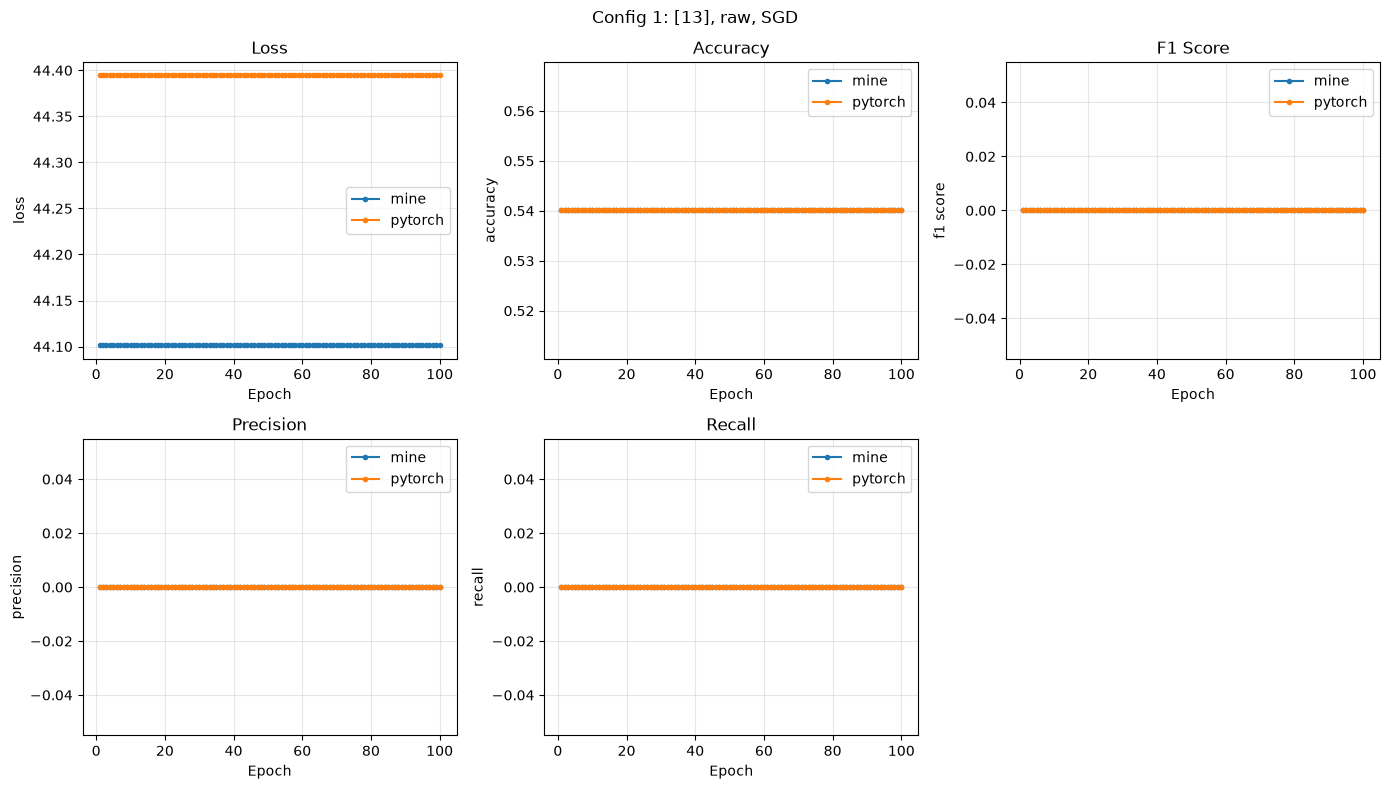

In [13]:
cfg1 = run_comparison(
    title="Config 1: [13], raw, SGD",
    hidden_layer_sizes=[13],
    X_train=X_train_raw_np,
    X_test=X_test_raw_np,
    y_train=y_train,
    y_test=y_test,
    optimizer_name="sgd",
)


## Config 2

`hidden=[32, 16, 8, 4, 2]`, **standardized**, **SGD**


Config 2: [32, 16, 8, 4, 2], standardized, SGD
init weights/biases close: [{'layer': 0, 'weights_close': True, 'biases_close': True, 'weights_max_abs_diff': 5.218801502060444e-08, 'biases_max_abs_diff': 0.0}, {'layer': 1, 'weights_close': True, 'biases_close': True, 'weights_max_abs_diff': 2.963260592458994e-08, 'biases_max_abs_diff': 0.0}, {'layer': 2, 'weights_close': True, 'biases_close': True, 'weights_max_abs_diff': 4.2107848985395435e-08, 'biases_max_abs_diff': 0.0}, {'layer': 3, 'weights_close': True, 'biases_close': True, 'weights_max_abs_diff': 4.1973394093730576e-08, 'biases_max_abs_diff': 0.0}, {'layer': 4, 'weights_close': True, 'biases_close': True, 'weights_max_abs_diff': 2.6438349953750162e-08, 'biases_max_abs_diff': 0.0}, {'layer': 5, 'weights_close': True, 'biases_close': True, 'weights_max_abs_diff': 7.226517891034678e-10, 'biases_max_abs_diff': 0.0}]
mine: {'loss': 0.612276244, 'accuracy': 0.5333333333, 'f1': 0.0, 'precision': 0.0, 'recall': 0.0}
pytorch: {'loss': 0.

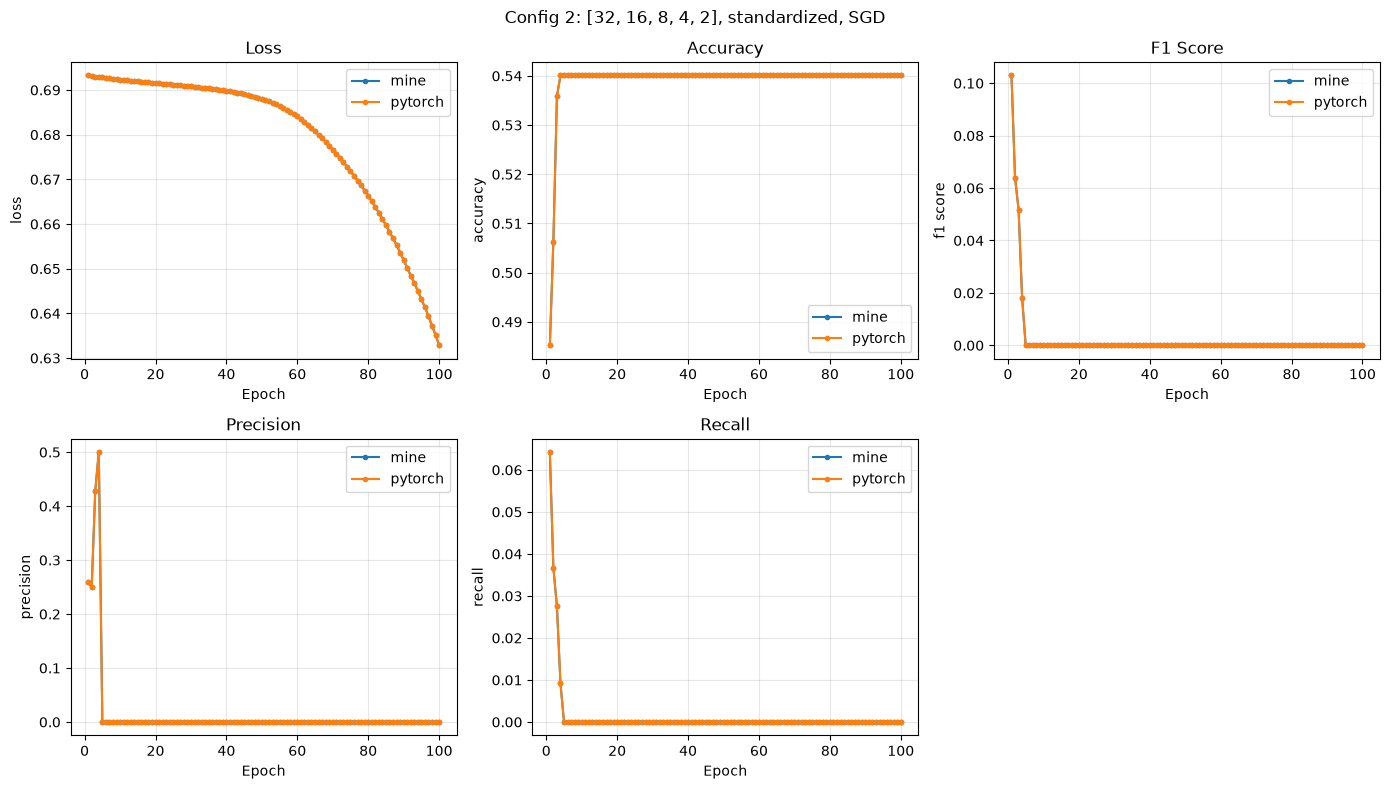

In [14]:
cfg2 = run_comparison(
    title="Config 2: [32, 16, 8, 4, 2], standardized, SGD",
    hidden_layer_sizes=[32, 16, 8, 4, 2],
    X_train=X_train_std,
    X_test=X_test_std,
    y_train=y_train,
    y_test=y_test,
    optimizer_name="sgd",
)


## Config 3

`hidden=[13, 13, 13]`, **standardized**, **Adam**, `max_iter=2000`


Config 3: [13, 13, 13], standardized, Adam
init weights/biases close: [{'layer': 0, 'weights_close': True, 'biases_close': True, 'weights_max_abs_diff': 5.218801502060444e-08, 'biases_max_abs_diff': 0.0}, {'layer': 1, 'weights_close': True, 'biases_close': True, 'weights_max_abs_diff': 5.05996806676734e-08, 'biases_max_abs_diff': 0.0}, {'layer': 2, 'weights_close': True, 'biases_close': True, 'weights_max_abs_diff': 2.821861011526039e-08, 'biases_max_abs_diff': 0.0}, {'layer': 3, 'weights_close': True, 'biases_close': True, 'weights_max_abs_diff': 6.582329334370307e-10, 'biases_max_abs_diff': 0.0}]
mine: {'loss': 8.0418734101, 'accuracy': 0.7333333333, 'f1': 0.7037037037, 'precision': 0.7307692308, 'recall': 0.6785714286}
pytorch: {'loss': 9.987436072031658, 'accuracy': 0.75, 'precision': 0.7407407407407407, 'recall': 0.7142857142857143, 'f1_score': 0.7272727272727273}
final weights/biases close: [{'layer': 0, 'weights_close': False, 'biases_close': False, 'weights_max_abs_diff': 0.115

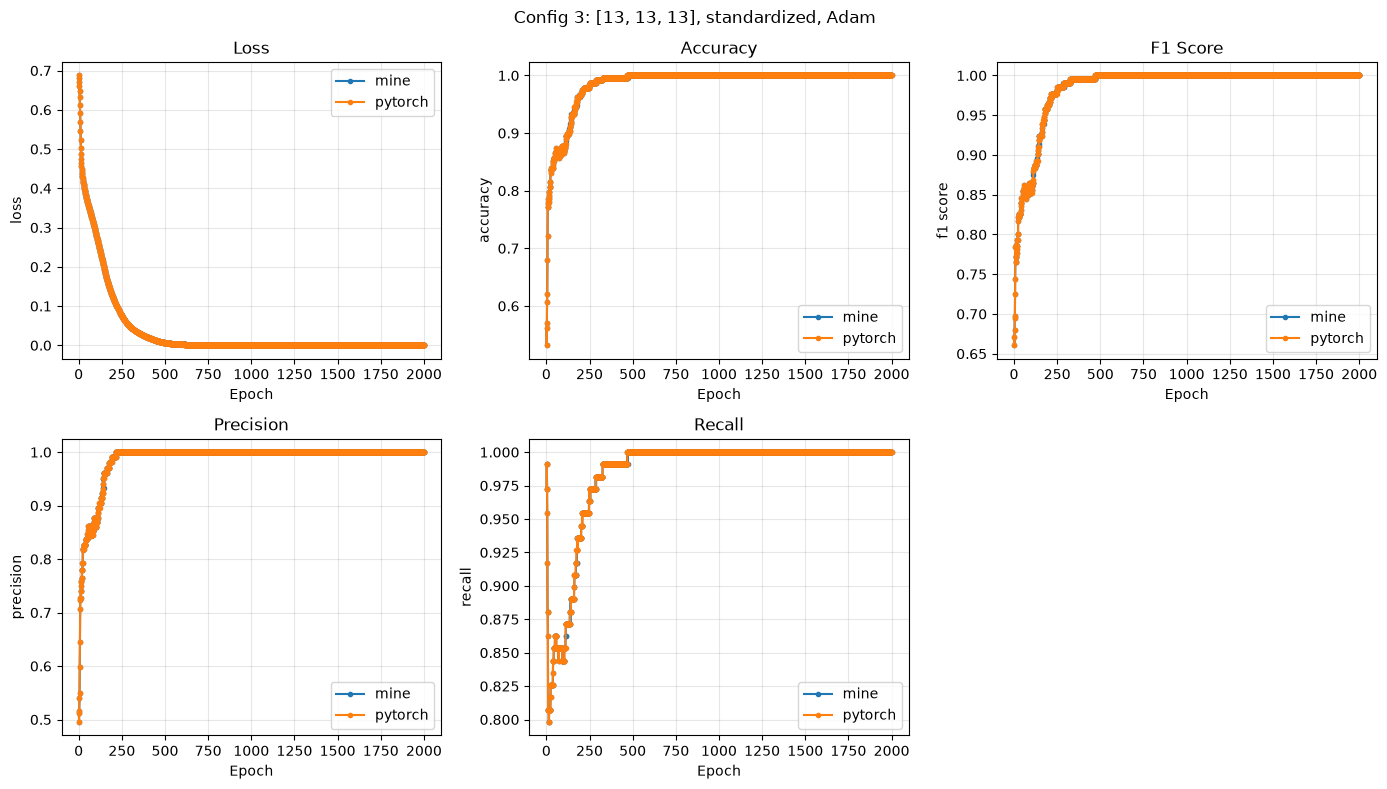

In [15]:
cfg3 = run_comparison(
    title="Config 3: [13, 13, 13], standardized, Adam",
    hidden_layer_sizes=[13, 13, 13],
    X_train=X_train_std,
    X_test=X_test_std,
    y_train=y_train,
    y_test=y_test,
    optimizer_name="adam",
    max_iter=2000,
)


## Summary


In [16]:
import pandas as pd

rows = []
for name, cfg in [
    ("[13] / raw / SGD", cfg1),
    ("[32,16,8,4,2] / std / SGD", cfg2),
    ("[13,13,13] / std / Adam", cfg3),
]:
    rows.append(
        {
            "config": name,
            "mine_loss": cfg["mine_metrics"]["loss"],
            "torch_loss": cfg["torch_metrics"]["loss"],
            "mine_acc": cfg["mine_metrics"]["accuracy"],
            "torch_acc": cfg["torch_metrics"]["accuracy"],
            "mine_f1": cfg["mine_metrics"]["f1"],
            "torch_f1": cfg["torch_metrics"]["f1_score"],
            "all_weights_close": all(r["weights_close"] for r in cfg["final_close"]),
            "all_biases_close": all(r["biases_close"] for r in cfg["final_close"]),
            "max_weight_diff": max(r["weights_max_abs_diff"] for r in cfg["final_close"]),
        }
    )

pd.DataFrame(rows)


,config,mine_loss,torch_loss,mine_acc,torch_acc,mine_f1,torch_f1,all_weights_close,all_biases_close,max_weight_diff
0,[13] / raw / SGD,43.792003,44.402609,0.533333,0.533333,0.000000,0.000000,True,True,8.156798e-08
1,"[32,16,8,4,2] / std / SGD",0.612276,0.612276,0.533333,0.533333,0.000000,0.000000,True,True,1.853157e-06
2,"[13,13,13] / std / Adam",8.041873,9.987436,0.733333,0.750000,0.703704,0.727273,False,False,1.752570e-01
